# CSC2042S
## Assignment 3: Neural Networks
### Total marks: 30


#### Assignment goal: Optimisation of a Neural Network for Image Classification

This Jupyter Notebook will guide you through building a neural network, understanding the training process including backpropagation), and experimentally discovering how hyperparameters impact performance.

**Dataset: Fashion-MNIST** - A collection of 70,000 grayscale images of clothing items, perfect for testing your models.
https://www.kaggle.com/datasets/zalando-research/fashionmnist

## Part 1: Setup and Data Loading

* Import necessary libraries, such as ``torch``, ``torch.nn``, ``torchvision.transforms``, ``matplotlib.pyplot``, etc.

* Load the dataset and transform the dataset (convert to tensors, normalise). Load the Fashion_mNIST dataset into ``DataLoader`` objects for training and validation.

Data partitioning: Download the 60,000-image training dataset and split it into:
50,000 samples for training.
10,000 samples for validation.
Take into account Normalisation.


In [1]:
# Part 1: imports, data loading, seeded split, training-only normalisation, and loaders
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset, random_split
from torchvision import datasets, transforms

# Seed relevant random-number generators. The dedicated generator below controls the split.
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# Load the raw training set with ToTensor only; calculate normalisation statistics after splitting.
data_dir = "./data"
raw_transform = transforms.ToTensor()
raw_dataset = datasets.FashionMNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=raw_transform,
)

# Make one reproducible 50,000/10,000 split and keep its original-dataset indices.
g = torch.Generator().manual_seed(SEED)
raw_train_subset, raw_val_subset = random_split(
    raw_dataset,
    [50_000, 10_000],
    generator=g,
)
train_indices = raw_train_subset.indices
val_indices = raw_val_subset.indices

# Compute population mean and standard deviation over every pixel in the training subset.
# Accumulating sums and squared sums avoids averaging per-batch standard deviations.
stats_loader = DataLoader(
    raw_train_subset,
    batch_size=1024,
    shuffle=False,
    num_workers=0,
)
pixel_sum = torch.zeros((), dtype=torch.float64)
pixel_sum_sq = torch.zeros((), dtype=torch.float64)
pixel_count = 0

for images, _ in stats_loader:
    pixels = images.to(torch.float64)
    pixel_sum += pixels.sum()
    pixel_sum_sq += pixels.square().sum()
    pixel_count += pixels.numel()

train_mean = (pixel_sum / pixel_count).item()
train_variance = (pixel_sum_sq / pixel_count - train_mean**2).clip(min=0.0)
train_std = train_variance.sqrt().item()
print(f"Training pixel mean: {train_mean:.8f}")
print(f"Training pixel std:  {train_std:.8f}")

# Rebuild the dataset with training-set statistics, then reuse the exact same split indices.
normalised_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((train_mean,), (train_std,)),
])
normalised_dataset = datasets.FashionMNIST(
    root=data_dir,
    train=True,
    download=True,
    transform=normalised_transform,
)
train_dataset = Subset(normalised_dataset, train_indices)
val_dataset = Subset(normalised_dataset, val_indices)

# Confirm the rebuilt subsets refer to the same original examples.
assert train_dataset.indices[:5] == train_indices[:5]
assert val_dataset.indices[:5] == val_indices[:5]

# Batch size 128 is a practical choice for this small 28x28 image dataset: it gives
# frequent gradient updates without requiring much memory. Only training is shuffled.
BATCH_SIZE = 128
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# Sanity checks: split lengths, image dimensions, and normalised pixel statistics.
assert len(train_dataset) == 50_000
assert len(val_dataset) == 10_000
images_batch, labels_batch = next(iter(train_loader))
print(f"Training examples: {len(train_dataset):,}; validation examples: {len(val_dataset):,}")
print(f"One training batch: images {tuple(images_batch.shape)}, labels {tuple(labels_batch.shape)}")
assert images_batch.ndim == 4 and tuple(images_batch.shape[1:]) == (1, 28, 28)

for split_name, split_dataset in (("training", train_dataset), ("validation", val_dataset)):
    check_loader = DataLoader(split_dataset, batch_size=1024, shuffle=False, num_workers=0)
    normalised_sum = torch.zeros((), dtype=torch.float64)
    normalised_sum_sq = torch.zeros((), dtype=torch.float64)
    normalised_count = 0
    for images, _ in check_loader:
        pixels = images.to(torch.float64)
        normalised_sum += pixels.sum()
        normalised_sum_sq += pixels.square().sum()
        normalised_count += pixels.numel()
    split_mean = (normalised_sum / normalised_count).item()
    split_variance = (normalised_sum_sq / normalised_count - split_mean**2).clip(min=0.0)
    split_std = split_variance.sqrt().item()
    print(f"Normalised {split_name} pixels: mean={split_mean:.6f}, std={split_std:.6f}")


Training pixel mean: 0.28574641
Training pixel std:  0.35288296
Training examples: 50,000; validation examples: 10,000
One training batch: images (128, 1, 28, 28), labels (128,)
Normalised training pixels: mean=0.000000, std=1.000000
Normalised validation pixels: mean=0.005002, std=1.002390


## Part 2: Building and Training a Baseline Model [5 Marks]

Before we can optimise a model, we need a baseline to compare against. We will build a simple, standard neural network and train it with default settings.

**Define the Network Architecture**
Define a PyTorch class for your neural network that inherits from ``nn.Module``. Your model should be a simple Multi-Layer Perceptron (MLP) with the following architecture:

* Input Layer (a flattening layer).

* Hidden Layer 1: 128 neurons, ReLU activation.

* Hidden Layer 2: 64 neurons, ReLU activation.

* Output Layer: 10 neurons (one for each class).

**Training Loop**
Complete the provided ``train_model`` function. You will need to fill in the essential steps of the training process within the loop. This is where you will implement the logic for the forward pass, loss calculation, backpropagation, and weight updates.

**Train the Baseline Model**
Create an instance of your model, define a loss function, and an optimiser. Train your model for 10 epochs and record its final accuracy on the validation set. This is your baseline accuracy.

In [2]:
# Define Network Architecture [2 Marks]
##################
# YOUR CODE HERE
class FashionMNISTMLP(nn.Module):
    # For the neural network, this function definition does define the baseline MLP and its optional dropout.
    def __init__(self, dropout_rate=0.0):
        # For the neural network, this function definition does create the layers with the requested dropout rate.
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.relu1 = nn.ReLU()
        self.dropout1 = nn.Dropout(p=dropout_rate)
        self.fc2 = nn.Linear(128, 64)
        self.relu2 = nn.ReLU()
        self.dropout2 = nn.Dropout(p=dropout_rate)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        # For the neural network, this function definition does map each image to ten raw class scores.
        x = self.flatten(x)
        x = self.dropout1(self.relu1(self.fc1(x)))
        x = self.dropout2(self.relu2(self.fc2(x)))
        x = self.fc3(x)
        return x
##################


In [3]:
# Updated Training and Evaluation skeleton [3 Marks]
# For the neural network, this function definition does train the model and track validation metrics.
def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=10):
    # Keep each batch on the same device as the model (CPU or GPU).
    device = next(model.parameters()).device

    # Store one training loss, validation loss, and validation accuracy per epoch.
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

    print("Starting Training...")
    for epoch in range(epochs):
        model.train() # Set model to training mode
        running_train_loss = 0.0
        for images, labels in train_loader:
            # 1. Forward Pass, Loss, Backward Pass, and Weight Update
            # ... YOUR TRAINING LOGIC ...
            images = images.to(device)
            labels = labels.to(device)

            # Clear gradients from the previous batch.
            optimizer.zero_grad()
            # Get the model's scores for this batch.
            outputs = model(images)
            # Compare the scores with the correct labels.
            loss = criterion(outputs, labels)
            # Calculate gradients for the model's parameters.
            loss.backward()
            # Update the model's parameters.
            optimizer.step()
            running_train_loss += loss.item() * images.size(0)

        # Calculate and store average training loss for the epoch
        epoch_train_loss = running_train_loss / len(train_loader.dataset)
        history['train_loss'].append(epoch_train_loss)

        # 2. Validation Phase
        model.eval() # Set model to evaluation mode
        running_val_loss = 0.0
        correct_predictions = 0
        total_predictions = 0

        with torch.no_grad(): # Disable gradient calculations
            for images, labels in val_loader:
                images = images.to(device)
                labels = labels.to(device)
                # Make predictions and calculate validation loss
                # ... YOUR VALIDATION LOGIC ...
                outputs = model(images)
                loss = criterion(outputs, labels)
                running_val_loss += loss.item() * images.size(0)
                # Calculate accuracy
                # ... YOUR ACCURACY LOGIC ...
                _, predicted = torch.max(outputs, dim=1)
                correct_predictions += (predicted == labels).sum().item()
                total_predictions += labels.size(0)

        # Calculate and store average validation loss and accuracy
        epoch_val_loss = running_val_loss / len(val_loader.dataset)
        epoch_val_acc = correct_predictions / total_predictions
        history['val_loss'].append(epoch_val_loss)
        history['val_acc'].append(epoch_val_acc)

        print(f"Epoch {epoch+1}/{epochs} - Train Loss: {epoch_train_loss:.4f}, Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_acc:.4f}")

    print("Finished Training")
    return history


In [4]:
# Train the Baseline Model [3 Marks]
##################
# YOUR CODE HERE
import os

# Keep the baseline results beside the downloaded data so they can be restored next time.
BASELINE_CHECKPOINT_PATH = os.path.join(data_dir, "baseline_checkpoint.pt")
BASELINE_SETTINGS = {
    "seed": SEED,
    "epochs": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": BATCH_SIZE,
    "dropout_rate": 0.0,
    "train_mean": train_mean,
    "train_std": train_std,
}

# Choose a GPU when one is available; otherwise, run the model on the CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Reset the random seed immediately before creating the baseline model.
torch.manual_seed(SEED)

# Create the required 128/64 MLP baseline with no dropout and move it to the device.
baseline_model = FashionMNISTMLP().to(device)

# Use cross-entropy because the model returns raw class scores (logits).
baseline_criterion = nn.CrossEntropyLoss()

# Keep Adam's default learning rate of 0.001 for the baseline.
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=0.001)

# Reuse the saved baseline when it matches these settings; otherwise, train it once.
if os.path.exists(BASELINE_CHECKPOINT_PATH):
    saved_baseline = torch.load(BASELINE_CHECKPOINT_PATH, map_location="cpu")
    if saved_baseline["settings"] != BASELINE_SETTINGS:
        raise ValueError(
            "The saved baseline uses different settings. Remove "
            f"{BASELINE_CHECKPOINT_PATH} only if you want to train a new baseline."
        )
    baseline_model.load_state_dict(saved_baseline["model_state"])
    baseline_history = saved_baseline["history"]
    baseline_accuracy = saved_baseline["accuracy"]
    print("Restored the saved baseline; no baseline training was needed.")
else:
    # Train the baseline for the required 10 epochs.
    baseline_history = train_model(
        baseline_model,
        train_loader,
        val_loader,
        baseline_criterion,
        baseline_optimizer,
        epochs=10,
    )
    baseline_accuracy = baseline_history["val_acc"][-1]

    # Save the trained baseline and its history for later sessions.
    baseline_state = {
        name: value.detach().cpu().clone()
        for name, value in baseline_model.state_dict().items()
    }
    baseline_temp_path = BASELINE_CHECKPOINT_PATH + ".tmp"
    torch.save({
        "settings": BASELINE_SETTINGS,
        "model_state": baseline_state,
        "history": baseline_history,
        "accuracy": baseline_accuracy,
    }, baseline_temp_path)
    os.replace(baseline_temp_path, BASELINE_CHECKPOINT_PATH)
    print(f"Saved baseline checkpoint to {BASELINE_CHECKPOINT_PATH}")

# Show the baseline validation accuracy used for comparison in Part 3.
print(f"Baseline validation accuracy after 10 epochs: {baseline_accuracy:.2%}")
##################


Restored the saved baseline; no baseline training was needed.
Baseline validation accuracy after 10 epochs: 88.51%


## Part 3: Hyperparameter Optimisation Experiment [15 Marks]

Remember the definition of hyperparameters - they are external configuration variables set before training begins, controlling the model's structure and the learning process itself.
The goal is to find the set of the values that beats the baseline accuracy.

**Design and run your experiment**
Choose **three** from the following categories of hyperparameters to investigate:
* Learning Processes
* Regularisation/Architecture
  

Write a script (e.g., using nested loops) that systematically trains and evaluates a new model for each combination of the hyperparameters you have chosen. Store the final validation accuracy for each run in a data structure.

### Hyperparameter choices and controls

I am comparing three optimizer choices: Adam, plain SGD, and SGD with momentum. The momentum option uses a value of 0.9. All three use the same learning rate, 0.001; this is Adam's default rate and gives the optimizer comparison one shared starting point.

The batch sizes are 128, 64, and 32. A batch size of 128 matches the baseline, while 64 and 32 show what happens when the model updates its weights more often. The dropout rates are 0.0, 0.2, and 0.5: 0.0 keeps the baseline unchanged, 0.2 adds modest regularisation, and 0.5 tests stronger regularisation.

This gives 27 combinations. The Adam/128/0.0 run matches the baseline settings. Every run keeps the 128/64 network architecture, the same training/validation split, seed 42, and 10 epochs; only optimizer, training batch size, and dropout rate vary. The validation loader stays fixed. The first run is timed and its duration is used to estimate the full sweep before the remaining runs continue.



### Saving progress between sessions

The baseline is saved after it is first trained. Part 3 now measures final training accuracy for every configuration and saves a new checkpoint after each completed run at `./data/part3_checkpoint_with_train_accuracy.pt`; the earlier Part 3 checkpoint is left untouched. Run the Part 3 cell once to train all 27 configurations. If the kernel stops, run the cell again to resume from the new checkpoint; only an unfinished configuration may need repeating.

The checkpoint files are stored in `./data/`, which is ignored by Git along with the downloaded dataset. After reopening VS Code, run the setup and model cells, then the baseline and Part 3 cells: they restore saved results and skip completed training. Once all 27 combinations are complete, these cells restore the histories and best model for Part 4 without retraining. Keep the checkpoint files until the report is finished, and exclude the `data` folder from the submission.


In [5]:
# Hyperparameter Optimisation Experiment [15 Marks]
##################
# YOUR CODE HERE
import os
import time

# Keep the model on the same device as the batches used by train_model.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
baseline_criterion = nn.CrossEntropyLoss()

# Load the baseline trained in Part 2 so a fresh kernel does not train it again.
BASELINE_CHECKPOINT_PATH = os.path.join(data_dir, "baseline_checkpoint.pt")
BASELINE_SETTINGS = {
    "seed": SEED,
    "epochs": 10,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": BATCH_SIZE,
    "dropout_rate": 0.0,
    "train_mean": train_mean,
    "train_std": train_std,
}
if not os.path.exists(BASELINE_CHECKPOINT_PATH):
    raise FileNotFoundError(
        "Run the baseline cell once to create its saved checkpoint before Part 3."
    )
saved_baseline = torch.load(BASELINE_CHECKPOINT_PATH, map_location="cpu")
if saved_baseline["settings"] != BASELINE_SETTINGS:
    raise ValueError("The saved baseline settings do not match the current Part 1/2 setup.")
baseline_model = FashionMNISTMLP().to(device)
baseline_model.load_state_dict(saved_baseline["model_state"])
baseline_history = saved_baseline["history"]
baseline_accuracy = saved_baseline["accuracy"]

# For the neural network, this function definition does measure final accuracy on a data loader.
def calculate_accuracy(model, loader):
    device = next(model.parameters()).device
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return correct / total

# Compare three optimiser choices, three batch sizes, and three dropout rates.
optimizer_types = ["Adam", "SGD", "SGD with momentum"]
batch_sizes = [128, 64, 32]
dropout_rates = [0.0, 0.2, 0.5]

# Keep one learning rate across optimisers so the experiment changes only the selected settings.
# 0.001 matches Adam's default and gives a conservative shared rate for the SGD variants.
EXPERIMENT_LEARNING_RATE = 0.001
SGD_MOMENTUM = 0.9
EXPERIMENT_EPOCHS = 10
RUNS_PER_SESSION = 27

total_combinations = len(optimizer_types) * len(batch_sizes) * len(dropout_rates)
experiment_settings = {
    "optimizer_types": optimizer_types,
    "batch_sizes": batch_sizes,
    "dropout_rates": dropout_rates,
    "learning_rate": EXPERIMENT_LEARNING_RATE,
    "sgd_momentum": SGD_MOMENTUM,
    "epochs": EXPERIMENT_EPOCHS,
    "training_accuracy": "final_eval_mode",
    "seed": SEED,
    "baseline_settings": BASELINE_SETTINGS,
}

# Keep the sweep checkpoint beside the Fashion-MNIST files; it is ignored by Git.
EXPERIMENT_CHECKPOINT_PATH = os.path.join(data_dir, "part3_checkpoint_with_train_accuracy.pt")
if os.path.exists(EXPERIMENT_CHECKPOINT_PATH):
    saved_experiment = torch.load(EXPERIMENT_CHECKPOINT_PATH, map_location="cpu")
    if saved_experiment["settings"] != experiment_settings:
        raise ValueError(
            "The saved Part 3 checkpoint uses different settings. Remove "
            f"{EXPERIMENT_CHECKPOINT_PATH} only if you want to start a new sweep."
        )
    experiment_results = saved_experiment["results"]
    best_model_state = saved_experiment["best_model_state"]
    print(
        f"Restored {len(experiment_results)}/{total_combinations} completed runs "
        "from the Part 3 checkpoint."
    )
else:
    experiment_results = []
    best_model_state = None

# Mark saved combinations so another session skips them instead of repeating them.
completed_configs = {
    (result["optimizer_type"], result["batch_size"], result["dropout_rate"])
    for result in experiment_results
}
best_val_accuracy = max(
    (result["val_acc"] for result in experiment_results),
    default=float("-inf"),
)
session_run_count = 0

# These nested loops cover every combination, starting with the baseline settings.
for optimizer_type in optimizer_types:
    for batch_size in batch_sizes:
        for dropout_rate in dropout_rates:
            if session_run_count >= RUNS_PER_SESSION:
                break

            config_key = (optimizer_type, batch_size, dropout_rate)
            if config_key in completed_configs:
                continue

            # Reset the seed so each run begins with the same model initialization and shuffle sequence.
            torch.manual_seed(SEED)

            # Create a fresh model with the baseline layer sizes and the current dropout rate.
            model = FashionMNISTMLP(dropout_rate=dropout_rate).to(device)

            # Create the selected optimiser with the shared learning rate.
            if optimizer_type == "Adam":
                optimizer = optim.Adam(model.parameters(), lr=EXPERIMENT_LEARNING_RATE)
                momentum = None
            elif optimizer_type == "SGD":
                optimizer = optim.SGD(model.parameters(), lr=EXPERIMENT_LEARNING_RATE)
                momentum = None
            else:
                optimizer = optim.SGD(
                    model.parameters(),
                    lr=EXPERIMENT_LEARNING_RATE,
                    momentum=SGD_MOMENTUM,
                )
                momentum = SGD_MOMENTUM

            # Rebuild only the training loader for this batch size; keep validation fixed.
            experiment_train_loader = DataLoader(
                train_dataset,
                batch_size=batch_size,
                shuffle=True,
                num_workers=0,
            )

            # Train this setting and keep the full history for the Part 4 plots.
            run_started = time.perf_counter()
            history = train_model(
                model,
                experiment_train_loader,
                val_loader,
                baseline_criterion,
                optimizer,
                epochs=EXPERIMENT_EPOCHS,
            )
            run_seconds = time.perf_counter() - run_started
            final_val_accuracy = history["val_acc"][-1]
            final_train_accuracy = calculate_accuracy(model, experiment_train_loader)
            print(f"Final training accuracy: {final_train_accuracy:.4f}")

            # Store the settings, final score, and epoch-by-epoch history for this run.
            experiment_results.append({
                "optimizer_type": optimizer_type,
                "batch_size": batch_size,
                "dropout_rate": dropout_rate,
                "learning_rate": EXPERIMENT_LEARNING_RATE,
                "momentum": momentum,
                "val_acc": final_val_accuracy,
                "train_acc": final_train_accuracy,
                "history": history,
            })
            completed_configs.add(config_key)
            session_run_count += 1

            # Keep a copy of the best weights so later runs cannot overwrite them.
            if final_val_accuracy > best_val_accuracy:
                best_val_accuracy = final_val_accuracy
                best_model_state = {
                    name: value.detach().cpu().clone()
                    for name, value in model.state_dict().items()
                }

            # Save after every finished run; replacing the old file keeps the last checkpoint intact.
            checkpoint_temp_path = EXPERIMENT_CHECKPOINT_PATH + ".tmp"
            torch.save({
                "settings": experiment_settings,
                "results": experiment_results,
                "best_model_state": best_model_state,
            }, checkpoint_temp_path)
            os.replace(checkpoint_temp_path, EXPERIMENT_CHECKPOINT_PATH)

            # Use the first new run in this session to estimate the remaining time.
            if session_run_count == 1:
                remaining_runs = total_combinations - len(experiment_results)
                estimated_remaining_seconds = run_seconds * remaining_runs
                print(
                    f"This run took {run_seconds / 60:.1f} minutes; "
                    f"estimated remaining sweep time: "
                    f"{estimated_remaining_seconds / 60:.1f} minutes."
                )

        if session_run_count >= RUNS_PER_SESSION:
            break
    if session_run_count >= RUNS_PER_SESSION:
        break

# Restore the best model so Part 4 can use it for the confusion matrix.
best_run = max(experiment_results, key=lambda result: result["val_acc"])
best_model = FashionMNISTMLP(dropout_rate=best_run["dropout_rate"]).to(device)
best_model.load_state_dict(best_model_state)
best_history = best_run["history"]

# Compare the best completed run with the saved baseline accuracy.
baseline_to_best_improvement = (best_run["val_acc"] - baseline_accuracy) * 100
remaining_combinations = total_combinations - len(experiment_results)
print(
    f"Checkpoint progress: {len(experiment_results)}/{total_combinations} "
    f"combinations complete; {remaining_combinations} remaining."
)
print(f"Baseline validation accuracy: {baseline_accuracy:.2%}")
print(
    "Best setting so far: "
    f"optimizer={best_run['optimizer_type']}, "
    f"batch_size={best_run['batch_size']}, "
    f"dropout_rate={best_run['dropout_rate']:.1f}, "
    f"validation_accuracy={best_run['val_acc']:.2%}"
)
print(f"Change from baseline: {baseline_to_best_improvement:+.2f} percentage points.")
if remaining_combinations:
    print(
        f"Saved progress to {EXPERIMENT_CHECKPOINT_PATH}. "
        f"Run this cell again to complete the next {min(RUNS_PER_SESSION, remaining_combinations)} runs."
    )
else:
    print("All hyperparameter combinations are complete; the saved results are ready for Part 4.")
##################
print("UPDATED PART 3 CELL: RUNS_PER_SESSION = 27; each completed run is checkpointed.")


Starting Training...
Epoch 1/10 - Train Loss: 0.5315, Val Loss: 0.4187, Val Acc: 0.8458
Epoch 2/10 - Train Loss: 0.3742, Val Loss: 0.3649, Val Acc: 0.8694
Epoch 3/10 - Train Loss: 0.3341, Val Loss: 0.3553, Val Acc: 0.8685
Epoch 4/10 - Train Loss: 0.3122, Val Loss: 0.3425, Val Acc: 0.8731
Epoch 5/10 - Train Loss: 0.2901, Val Loss: 0.3337, Val Acc: 0.8775
Epoch 6/10 - Train Loss: 0.2713, Val Loss: 0.3140, Val Acc: 0.8829
Epoch 7/10 - Train Loss: 0.2587, Val Loss: 0.3153, Val Acc: 0.8866
Epoch 8/10 - Train Loss: 0.2467, Val Loss: 0.3605, Val Acc: 0.8692
Epoch 9/10 - Train Loss: 0.2333, Val Loss: 0.3467, Val Acc: 0.8747
Epoch 10/10 - Train Loss: 0.2243, Val Loss: 0.3312, Val Acc: 0.8851
Finished Training
Final training accuracy: 0.9185
This run took 5.1 minutes; estimated remaining sweep time: 132.6 minutes.
Starting Training...
Epoch 1/10 - Train Loss: 0.6099, Val Loss: 0.4208, Val Acc: 0.8456
Epoch 2/10 - Train Loss: 0.4253, Val Loss: 0.3708, Val Acc: 0.8619
Epoch 3/10 - Train Loss: 0.38

## Part 4: Analysis and Report  [10 Marks]
In this final section, you will analyse the results of your experiment and report your findings.

* Present your experimental results in a well-formatted table (e.g., a Pandas DataFrame) showing the combination of hyperparameters and the final validation accuracy for each run. [2 Marks]
* The marking rubric also asks for a training-accuracy table; Part 3 records final training accuracy for each configuration.
* Create at least two visualisations to help interpret your results: [4 Marks]
    * Hyperparameter Impact: Create a bar chart or heatmap that clearly compares the performance of your different hyperparameter combinations.
    * Loss Curves. Plot the training and validation loss curves (loss vs. epochs) for your baseline model and your single best-performing model on the same graph. This is crucial for comparing model convergence and overfitting.
    * Confusion Matrix. Generate and display a confusion matrix for your best model's predictions on the validation set. This will help you see which specific clothing items are being confused.
* Interpret your results. [4 Marks]
  * Answer the following questions concisely, using evidence from your table and plots to support your claims:
    * Best vs. Baseline: Which combination of hyperparameters produced the best model? How much did it improve upon the baseline accuracy?
    * Hyperparameter Influence: Which hyperparameter had the most significant impact on performance? Explain why you think certain values worked better than others.
    * Overfitting Analysis: By comparing the loss curves of your baseline and best models, analyze the degree of overfitting. Did your hyperparameter tuning help mitigate overfitting? How can you tell from the plot?
    * Error Analysis: Look at your confusion matrix. Identify two classes that the model frequently confuses. Propose a reason for this confusion by considering the visual characteristics of the items in those classes.

Saved Part 3 runs: 27 / 27
Validation accuracy (best first)


,Run,Optimizer,Batch size,Dropout rate,Validation accuracy
0,Experiment,Adam,64,0.2,0.8908
1,Experiment,Adam,64,0.0,0.8890
2,Experiment,Adam,32,0.0,0.8889
3,Experiment,Adam,128,0.2,0.8873
4,Experiment,Adam,128,0.0,0.8851
5,Baseline,Adam,128,0.0,0.8851
6,Experiment,Adam,32,0.2,0.8827
7,Experiment,SGD with momentum,32,0.2,0.8769
8,Experiment,SGD with momentum,32,0.0,0.8759
9,Experiment,Adam,64,0.5,0.8715


Training accuracy


,Run,Optimizer,Batch size,Dropout rate,Training accuracy
0,Experiment,Adam,64,0.2,0.9111
1,Experiment,Adam,64,0.0,0.9226
2,Experiment,Adam,32,0.0,0.9224
3,Experiment,Adam,128,0.2,0.9108
4,Experiment,Adam,128,0.0,0.9185
5,Baseline,Adam,128,0.0,0.9185
6,Experiment,Adam,32,0.2,0.9058
7,Experiment,SGD with momentum,32,0.2,0.8910
8,Experiment,SGD with momentum,32,0.0,0.8939
9,Experiment,Adam,64,0.5,0.8831


Best setting so far: optimizer=Adam, batch size=64, dropout=0.2
Best validation accuracy: 0.8908
Baseline validation accuracy: 0.8851
Change from baseline: +0.57 percentage points.


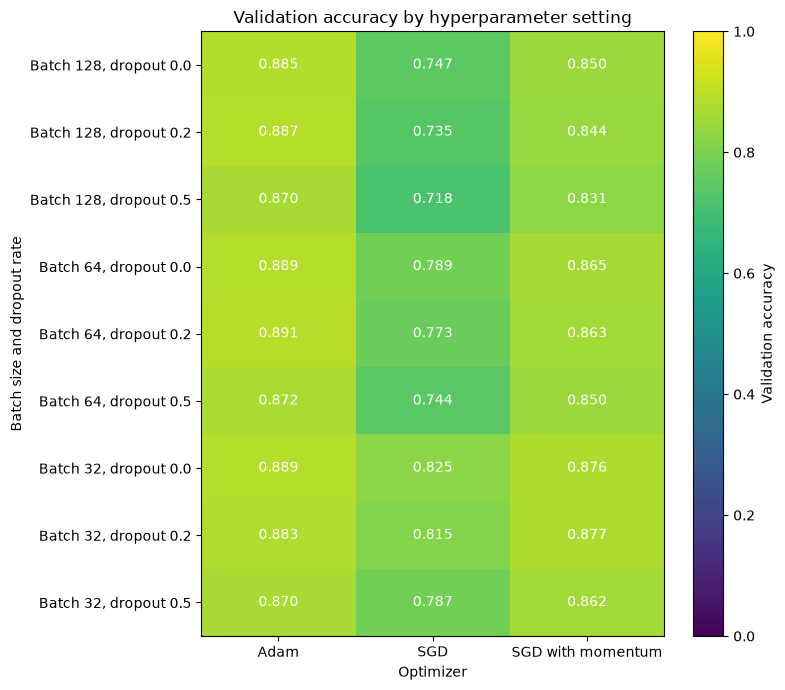

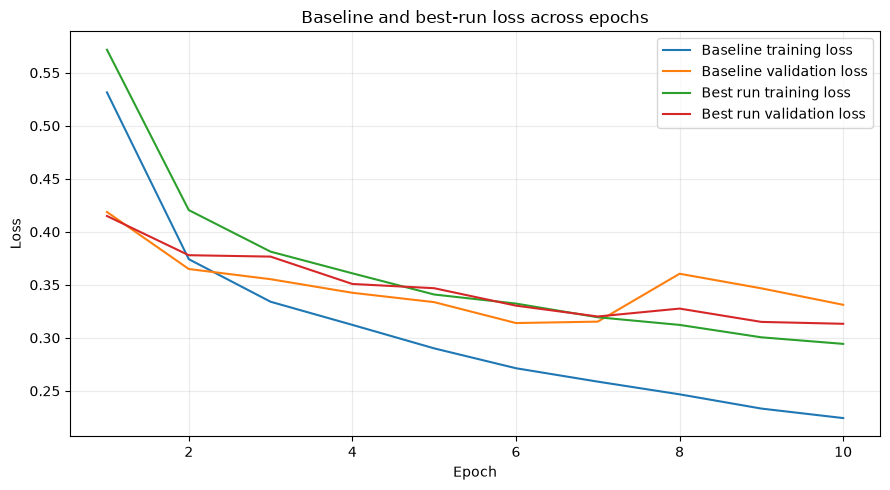

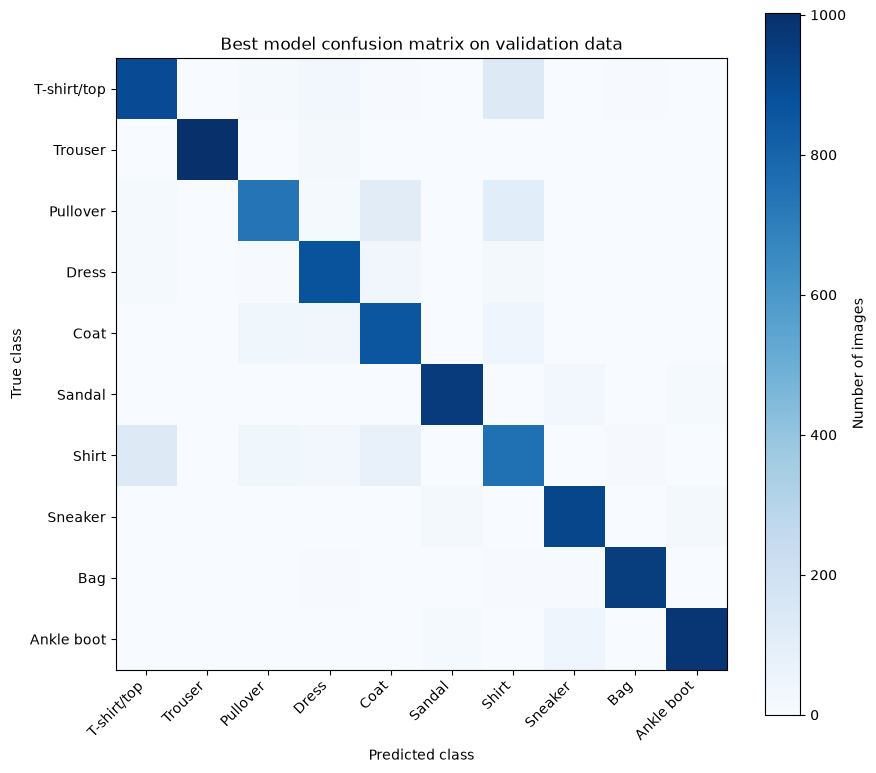

Most frequently confused class pairs:
T-shirt/top and Shirt: 258 errors
Pullover and Coat: 150 errors

Mean validation accuracy by Optimizer:


,Mean validation accuracy
Optimizer,
Adam,0.8817
SGD with momentum,0.8576
SGD,0.7703


Range across Optimizer values: 0.1113

Mean validation accuracy by Batch size:


,Mean validation accuracy
Batch size,
32,0.8536
64,0.8374
128,0.8186


Range across Batch size values: 0.0349

Mean validation accuracy by Dropout rate:


,Mean validation accuracy
Dropout rate,
0.000000,0.8461
0.200000,0.8409
0.500000,0.8226


Range across Dropout rate values: 0.0235


In [6]:
# I read the saved sweep here, so this cell does not train the models again.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

part3_checkpoint_path = os.path.join(data_dir, "part3_checkpoint_with_train_accuracy.pt")
if not os.path.exists(part3_checkpoint_path):
    raise FileNotFoundError(
        f"Part 3 checkpoint not found: {part3_checkpoint_path}. Run Part 3 first."
    )

saved_experiment = torch.load(part3_checkpoint_path, map_location="cpu")
experiment_results = saved_experiment["results"]
if not experiment_results:
    raise ValueError("The Part 3 checkpoint has no completed runs yet.")

# I check progress so I know whether these results cover the full experiment.
experiment_settings = saved_experiment["settings"]
total_combinations = (
    len(experiment_settings["optimizer_types"])
    * len(experiment_settings["batch_sizes"])
    * len(experiment_settings["dropout_rates"])
)
print(f"Saved Part 3 runs: {len(experiment_results)} / {total_combinations}")
if len(experiment_results) < total_combinations:
    print("These results are partial. Finish the Part 3 sweep, then rerun this cell.")

# For the neural network, this function definition does calculate final training accuracy.
def calculate_accuracy(model, loader):
    device = next(model.parameters()).device
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            predictions = model(images).argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)
    return correct / total

baseline_train_accuracy = calculate_accuracy(baseline_model, train_loader)

# I put every completed run into one row, with the baseline included for comparison.
experiment_rows = [
    {
        "Run": "Experiment",
        "Optimizer": result["optimizer_type"],
        "Batch size": result["batch_size"],
        "Dropout rate": result["dropout_rate"],
        "Training accuracy": result["train_acc"],
        "Validation accuracy": result["val_acc"],
    }
    for result in experiment_results
]
baseline_row = {
    "Run": "Baseline",
    "Optimizer": "Adam",
    "Batch size": BATCH_SIZE,
    "Dropout rate": 0.0,
    "Training accuracy": baseline_train_accuracy,
    "Validation accuracy": baseline_accuracy,
}
results_df = pd.DataFrame(experiment_rows + [baseline_row])
results_df = results_df.sort_values(
    "Validation accuracy", ascending=False
).reset_index(drop=True)

# This is the results table requested in the brief.
print("Validation accuracy (best first)")
display(
    results_df[
        ["Run", "Optimizer", "Batch size", "Dropout rate", "Validation accuracy"]
    ].style.format({"Dropout rate": "{:.1f}", "Validation accuracy": "{:.4f}"})
)

# The rubric also asks for training accuracy, which Part 3 now saves for each run.
print("Training accuracy")
display(
    results_df[
        ["Run", "Optimizer", "Batch size", "Dropout rate", "Training accuracy"]
    ].style.format({"Dropout rate": "{:.1f}", "Training accuracy": "{:.4f}"})
)

best_run = max(experiment_results, key=lambda result: result["val_acc"])
best_history = best_run["history"]
best_model_state = saved_experiment["best_model_state"]
if best_model_state is None:
    raise ValueError("The checkpoint has no saved best-model weights.")

# I compare the best completed setting with the baseline.
improvement_pp = (best_run["val_acc"] - baseline_accuracy) * 100
print(
    f"Best setting so far: optimizer={best_run['optimizer_type']}, "
    f"batch size={best_run['batch_size']}, dropout={best_run['dropout_rate']:.1f}"
)
print(f"Best validation accuracy: {best_run['val_acc']:.4f}")
print(f"Baseline validation accuracy: {baseline_accuracy:.4f}")
print(f"Change from baseline: {improvement_pp:+.2f} percentage points.")

# I compare accuracy across all optimizer, batch-size, and dropout settings.
optimizer_types = experiment_settings["optimizer_types"]
batch_sizes = experiment_settings["batch_sizes"]
dropout_rates = experiment_settings["dropout_rates"]
config_labels = [
    f"Batch {batch_size}, dropout {dropout_rate:.1f}"
    for batch_size in batch_sizes
    for dropout_rate in dropout_rates
]
accuracy_grid = np.full((len(config_labels), len(optimizer_types)), np.nan)
for result in experiment_results:
    row = (
        batch_sizes.index(result["batch_size"]) * len(dropout_rates)
        + dropout_rates.index(result["dropout_rate"])
    )
    column = optimizer_types.index(result["optimizer_type"])
    accuracy_grid[row, column] = result["val_acc"]

fig, ax = plt.subplots(figsize=(8, 7))
heatmap = ax.imshow(
    np.ma.masked_invalid(accuracy_grid), aspect="auto", vmin=0, vmax=1, cmap="viridis"
)
heatmap.cmap.set_bad("#dddddd")
ax.set_xticks(range(len(optimizer_types)), labels=optimizer_types)
ax.set_yticks(range(len(config_labels)), labels=config_labels)
ax.set_title("Validation accuracy by hyperparameter setting")
ax.set_xlabel("Optimizer")
ax.set_ylabel("Batch size and dropout rate")
for row in range(accuracy_grid.shape[0]):
    for column in range(accuracy_grid.shape[1]):
        value = accuracy_grid[row, column]
        if not np.isnan(value):
            ax.text(column, row, f"{value:.3f}", ha="center", va="center", color="white")
fig.colorbar(heatmap, ax=ax, label="Validation accuracy")
fig.tight_layout()
plt.show()

# I compare the baseline loss curves with the best completed run.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(range(1, len(baseline_history["train_loss"]) + 1), baseline_history["train_loss"], label="Baseline training loss")
ax.plot(range(1, len(baseline_history["val_loss"]) + 1), baseline_history["val_loss"], label="Baseline validation loss")
ax.plot(range(1, len(best_history["train_loss"]) + 1), best_history["train_loss"], label="Best run training loss")
ax.plot(range(1, len(best_history["val_loss"]) + 1), best_history["val_loss"], label="Best run validation loss")
ax.set_title("Baseline and best-run loss across epochs")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

# I rebuild the best model from its saved weights and check it on the validation set.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
best_model = FashionMNISTMLP(dropout_rate=best_run["dropout_rate"]).to(device)
best_model.load_state_dict(best_model_state)
best_model.eval()
class_names = raw_dataset.classes
confusion = np.zeros((len(class_names), len(class_names)), dtype=np.int64)
with torch.no_grad():
    for images, labels in val_loader:
        predictions = best_model(images.to(device)).argmax(dim=1).cpu().numpy()
        np.add.at(confusion, (labels.numpy(), predictions), 1)

fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(confusion, cmap="Blues")
ax.set_title("Best model confusion matrix on validation data")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_xticks(range(len(class_names)), labels=class_names, rotation=45, ha="right")
ax.set_yticks(range(len(class_names)), labels=class_names)
fig.colorbar(image, ax=ax, label="Number of images")
fig.tight_layout()
plt.show()

# I list the most confused class pairs to help with the error-analysis paragraph.
confused_pairs = [
    (confusion[a, b] + confusion[b, a], a, b)
    for a in range(len(class_names))
    for b in range(a + 1, len(class_names))
]
confused_pairs.sort(reverse=True)
print("Most frequently confused class pairs:")
for count, first, second in confused_pairs[:2]:
    print(f"{class_names[first]} and {class_names[second]}: {count} errors")

# These averages help me compare the overall effect of each hyperparameter.
experiment_df = pd.DataFrame(experiment_rows)
for column in ["Optimizer", "Batch size", "Dropout rate"]:
    means = experiment_df.groupby(column)["Validation accuracy"].mean().sort_values(ascending=False)
    print(f"\nMean validation accuracy by {column}:")
    display(means.to_frame("Mean validation accuracy").style.format("{:.4f}"))
    print(f"Range across {column} values: {means.max() - means.min():.4f}")
